# Proyecto ML - Visión Artificial
## Entrega 1: Implementación Básica con CNN (Fine-Tuning)
### Dataset: BreastMNIST — Ultrasonido de mama (Clasificación Binaria)
**Alumno:** Nicolás Barrientos Sabaleta  
**Curso:** Aprendizaje de Máquina — CINF104.202610.7917  
**Resolución:** 28×28 píxeles  
**Modelo base:** EfficientNetB0 (pre-entrenado en ImageNet)


---
## 0. Instalación de dependencias

In [ ]:
!pip install medmnist --quiet

## 1. Importaciones

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, accuracy_score, f1_score
)

import medmnist
from medmnist import BreastMNIST, INFO

print('TensorFlow version:', tf.__version__)
print('MedMNIST version:', medmnist.__version__)
print('GPU disponible:', tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
MedMNIST version: 3.0.2
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## 2. Contexto clínico del problema

El **cáncer de mama** es uno de los tipos de cáncer más frecuentes a nivel mundial. El diagnóstico temprano mediante ultrasonido es clave para mejorar el pronóstico del paciente.

**BreastMNIST** está basado en el dataset público de ultrasonido de mama de Zhang et al. (2020), que contiene imágenes en escala de grises redimensionadas a 28×28 píxeles. La tarea consiste en distinguir entre:

- **Clase 0**: Maligno (tumor canceroso)
- **Clase 1**: Normal / Benigno

La relevancia clínica es alta: un sistema automatizado puede asistir a radiólogos en la detección temprana, reduciendo errores diagnósticos y tiempos de análisis.

---
## 3. Carga y exploración del dataset

In [ ]:
# Información del dataset desde MedMNIST
info = INFO['breastmnist']
print('Descripción:', info['description'])
print('Tarea:', info['task'])
print('Clases:', info['label'])
print('N° canales:', info['n_channels'])
print('N° clases:', len(info['label']))
print('N° muestras por split:', info['n_samples'])

Descripción: The BreastMNIST is based on a dataset of 780 breast ultrasound images. It is categorized into 3 classes: normal, benign, and malignant. As we use low-resolution images, we simplify the task into binary classification by combining normal and benign as positive and classifying them against malignant as negative. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images of 1×500×500 are resized into 1×28×28.
Tarea: binary-class
Clases: {'0': 'malignant', '1': 'normal, benign'}
N° canales: 1
N° clases: 2
N° muestras por split: {'train': 546, 'val': 78, 'test': 156}


In [ ]:
# Descarga y carga del dataset (split hold-out oficial de MedMNIST)
train_dataset = BreastMNIST(split='train', download=True)
val_dataset   = BreastMNIST(split='val',   download=True)
test_dataset  = BreastMNIST(split='test',  download=True)

# Extraer arrays numpy
X_train = np.array([np.array(img) for img, _ in train_dataset])
y_train = np.array([label.item() for _, label in train_dataset])

X_val   = np.array([np.array(img) for img, _ in val_dataset])
y_val   = np.array([label.item() for _, label in val_dataset])

X_test  = np.array([np.array(img) for img, _ in test_dataset])
y_test  = np.array([label.item() for _, label in test_dataset])

print(f'Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}')
print(f'Etiquetas únicas: {np.unique(y_train)}')

Train: (546, 28, 28), Val: (78, 28, 28), Test: (156, 28, 28)
Etiquetas únicas: [0 1]


### 3.1 Análisis exploratorio de datos (EDA)

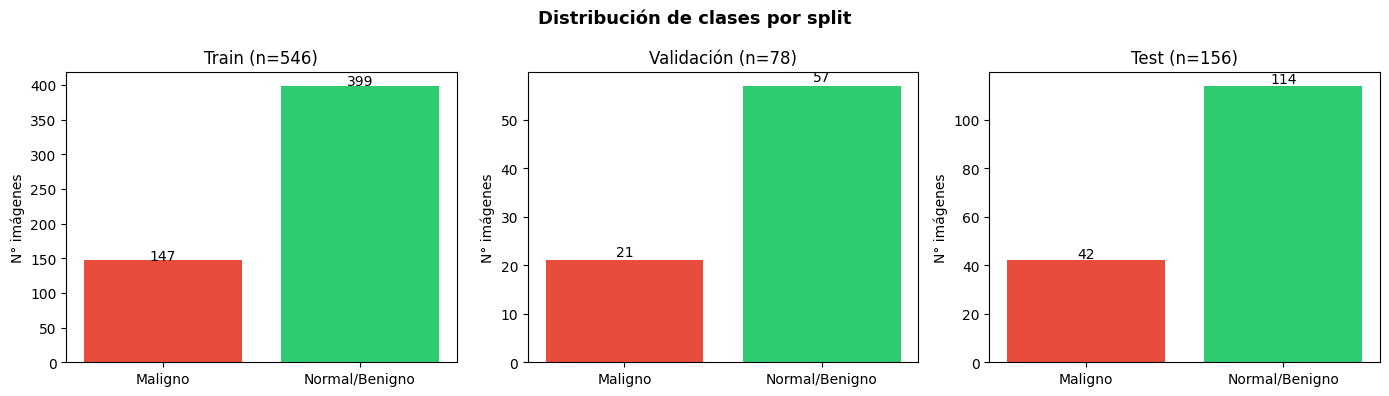


Resumen distribución:
  Train: Maligno=147 (26.9%), Benigno/Normal=399 (73.1%)
  Val: Maligno=21 (26.9%), Benigno/Normal=57 (73.1%)
  Test: Maligno=42 (26.9%), Benigno/Normal=114 (73.1%)


In [ ]:
class_names = {0: 'Maligno', 1: 'Normal/Benigno'}

# Distribución de clases
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (X, y, split) in zip(axes, [
    (X_train, y_train, 'Train'),
    (X_val,   y_val,   'Validación'),
    (X_test,  y_test,  'Test')
]):
    counts = Counter(y)
    bars = ax.bar([class_names[k] for k in sorted(counts)],
                  [counts[k] for k in sorted(counts)],
                  color=['#e74c3c', '#2ecc71'])
    ax.set_title(f'{split} (n={len(y)})')
    ax.set_ylabel('N° imágenes')
    for bar, val in zip(bars, [counts[k] for k in sorted(counts)]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(val), ha='center', fontsize=10)
plt.suptitle('Distribución de clases por split', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nResumen distribución:')
for split, y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    counts = Counter(y)
    total = len(y)
    print(f'  {split}: Maligno={counts[0]} ({100*counts[0]/total:.1f}%), '
          f'Benigno/Normal={counts[1]} ({100*counts[1]/total:.1f}%)')

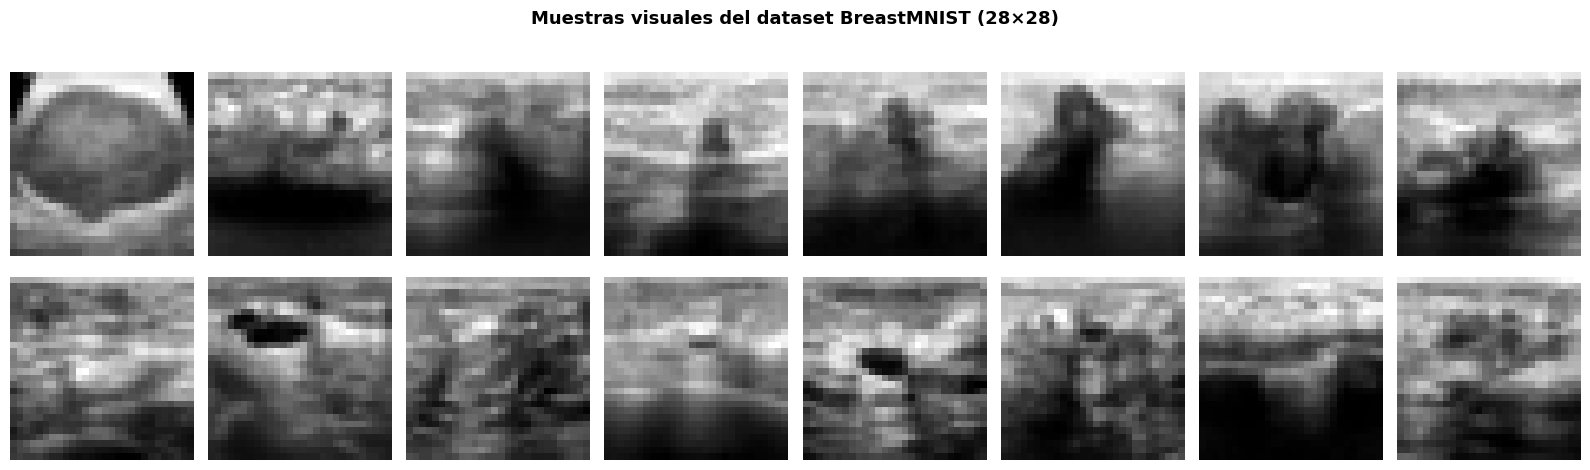

In [ ]:
# Muestras visuales por clase
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for cls_idx, cls in enumerate([0, 1]):
    idxs = np.where(y_train == cls)[0][:8]
    for col, idx in enumerate(idxs):
        axes[cls_idx, col].imshow(X_train[idx], cmap='gray')
        axes[cls_idx, col].axis('off')
        if col == 0:
            axes[cls_idx, col].set_ylabel(class_names[cls], fontsize=11, rotation=90)
plt.suptitle('Muestras visuales del dataset BreastMNIST (28×28)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Estadísticas del conjunto de entrenamiento:
  Forma de imágenes: (546, 28, 28)
  Valor mínimo: 0, Máximo: 255
  Media: 83.53, Desv. estándar: 52.46


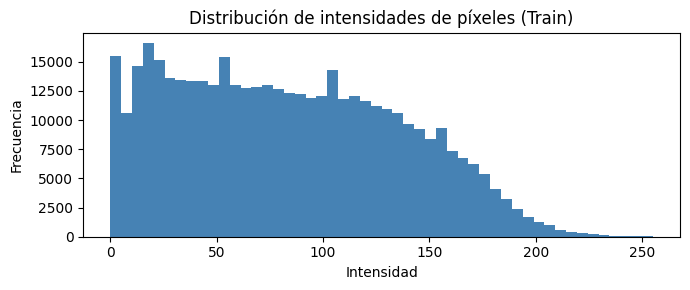

In [ ]:
# Estadísticas de intensidad de píxeles
print('Estadísticas del conjunto de entrenamiento:')
print(f'  Forma de imágenes: {X_train.shape}')
print(f'  Valor mínimo: {X_train.min()}, Máximo: {X_train.max()}')
print(f'  Media: {X_train.mean():.2f}, Desv. estándar: {X_train.std():.2f}')

plt.figure(figsize=(7, 3))
plt.hist(X_train.flatten(), bins=50, color='steelblue', edgecolor='none')
plt.title('Distribución de intensidades de píxeles (Train)')
plt.xlabel('Intensidad'); plt.ylabel('Frecuencia')
plt.tight_layout(); plt.show()

---
## 4. Preprocesamiento y preparación del pipeline

In [ ]:
IMG_SIZE = 32  # EfficientNetB0 requiere mínimo 32x32 (subimos desde 28x28)
BATCH_SIZE = 32

def preprocess(X, y):
    if X.ndim == 3:
        X = X[..., np.newaxis]
    # Resize de 28x28 a 32x32
    X_resized = tf.image.resize(X, [IMG_SIZE, IMG_SIZE]).numpy()
    # Replicar a 3 canales
    X_resized = np.repeat(X_resized, 3, axis=-1)
    # Normalizar a [0, 1]
    X_resized = X_resized.astype(np.float32) / 255.0
    return X_resized, y.astype(np.int32)

X_train_p, y_train_p = preprocess(X_train, y_train)
X_val_p,   y_val_p   = preprocess(X_val,   y_val)
X_test_p,  y_test_p  = preprocess(X_test,  y_test)

print('Formas tras preprocesamiento:')
print(f'  Train: {X_train_p.shape}, Val: {X_val_p.shape}, Test: {X_test_p.shape}')

Formas tras preprocesamiento:
  Train: (546, 32, 32, 3), Val: (78, 32, 32, 3), Test: (156, 32, 32, 3)


In [ ]:
# Recrear pipelines con el tamaño correcto (32x32)
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name='data_augmentation')

def make_dataset(X, y, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=42)
    ds = ds.batch(BATCH_SIZE)
    if augment:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train_p, y_train_p, augment=True, shuffle=True)
val_ds   = make_dataset(X_val_p,   y_val_p)
test_ds  = make_dataset(X_test_p,  y_test_p)

# Verificar forma
for batch_x, batch_y in train_ds.take(1):
    print('Forma del batch:', batch_x.shape)  # Debe decir (32, 32, 32, 3)

Forma del batch: (32, 32, 32, 3)


---
## 5. Construcción del modelo con fine-tuning

### Estrategia:
1. **Fase 1 — Feature Extraction**: Congelar la base EfficientNetB0, entrenar solo el clasificador nuevo.
2. **Fase 2 — Fine-Tuning**: Descongelar las últimas capas de la base y reentrenar con learning rate bajo.

In [ ]:
def build_model(trainable_base=False, fine_tune_at=None):
    base_model = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)  # ahora 32x32x3
    )
    base_model.trainable = trainable_base
    if trainable_base and fine_tune_at is not None:
        for layer in base_model.layers[:-fine_tune_at]:
            layer.trainable = False

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs)
    return model, base_model

### 5.1 Fase 1: Feature Extraction (base congelada)

In [ ]:
EPOCHS_PHASE1 = 20

model, base_model = build_model(trainable_base=False)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

model.summary()
print(f'\nCapas entrenables (Fase 1): {sum(1 for l in model.layers if l.trainable)}')

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1, 1, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,136,740 (15.78 MB)

 Trainable params: 84,609 (330.50 KB)

 Non-trainable params: 4,052,131 (15.46 MB)


Capas entrenables (Fase 1): 7


In [ ]:
callbacks_phase1 = [
    EarlyStopping(monitor='val_auc', patience=5, restore_best_weights=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks_phase1,
    verbose=1
)

print('\nFase 1 completada.')

Epoch 1/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 72s 2s/step - accuracy: 0.6465 - auc: 0.4665 - loss: 0.7468 - val_accuracy: 0.7308 - val_auc: 0.5000 - val_loss: 0.5857 - learning_rate: 0.0010
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6832 - auc: 0.5297 - loss: 0.6976 - val_accuracy: 0.7308 - val_auc: 0.5000 - val_loss: 0.5847 - learning_rate: 0.0010
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6923 - auc: 0.4866 - loss: 0.7078 - val_accuracy: 0.7308 - val_auc: 0.5000 - val_loss: 0.5824 - learning_rate: 0.0010
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6960 - auc: 0.5187 - loss: 0.6971 - val_accuracy: 0.7308 - val_auc: 0.5000 - val_loss: 0.5855 - learning_rate: 0.0010
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6410 - auc: 0.5021 - loss: 0.7141 - val_accuracy: 0.7308 - val_auc: 0.4937 - val_loss: 0.5832 - learning_rate: 0.0010
Epoch 6/20
17/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7032 - auc: 0.5145 - 

### 5.2 Fase 2: Fine-Tuning (descongelar últimas capas)

In [ ]:
EPOCHS_PHASE2 = 20
FINE_TUNE_AT  = 20  # Descongelar las últimas 20 capas de la base

# Descongelar capas superiores del modelo base
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_AT]:
    layer.trainable = False

trainable_count = sum(1 for l in model.layers if l.trainable)
print(f'Capas entrenables (Fase 2): {trainable_count}')

# Recompilar con LR mucho más bajo para fine-tuning
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

callbacks_phase2 = [
    EarlyStopping(monitor='val_auc', patience=7, restore_best_weights=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE2,
    callbacks=callbacks_phase2,
    verbose=1
)

print('\nFase 2 (fine-tuning) completada.')

Capas entrenables (Fase 2): 8
Epoch 1/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.5476 - auc: 0.4707 - loss: 1.0070 - val_accuracy: 0.7308 - val_auc: 0.5000 - val_loss: 0.5878 - learning_rate: 1.0000e-05
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5330 - auc: 0.4995 - loss: 0.9447 - val_accuracy: 0.7308 - val_auc: 0.5000 - val_loss: 0.5857 - learning_rate: 1.0000e-05
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.5165 - auc: 0.4455 - loss: 0.9854 - val_accuracy: 0.7308 - val_auc: 0.5025 - val_loss: 0.5834 - learning_rate: 1.0000e-05
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5861 - auc: 0.5125 - loss: 0.8422 - val_accuracy: 0.7308 - val_auc: 0.6078 - val_loss: 0.5822 - learning_rate: 1.0000e-05
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5440 - auc: 0.4725 - loss: 0.8888 - val_accuracy: 0.7308 - val_auc: 0.5088 - val_loss: 0.5837 - learning_rate: 1.0000e-05
Epoch 6/20
18/18 ━━━━━━━━━━━━━━━━━━━

---
## 6. Visualización de curvas de entrenamiento

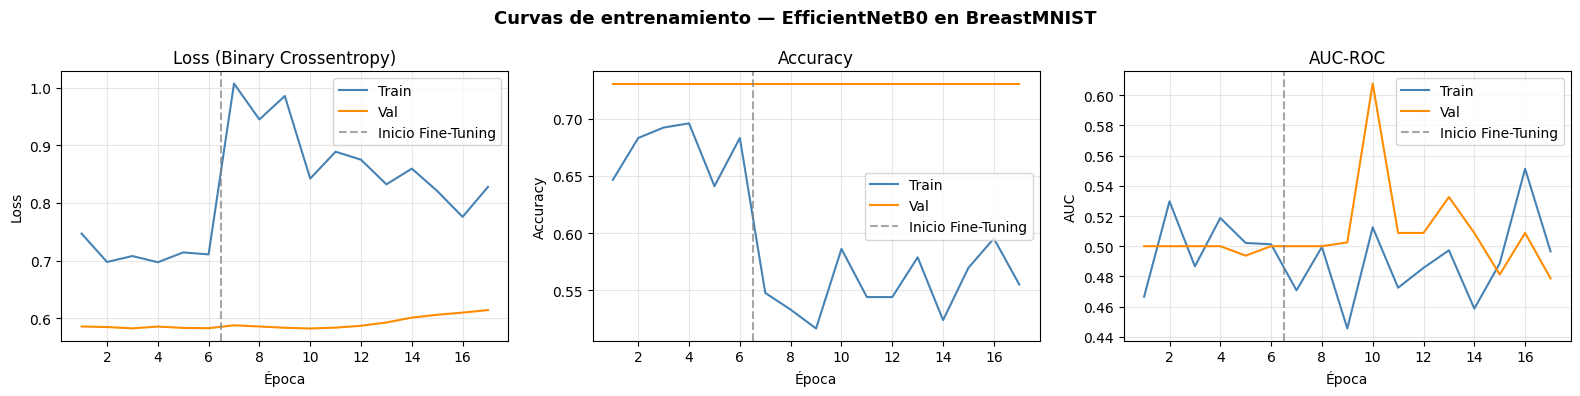

In [ ]:
def merge_histories(h1, h2):
    """Concatena dos historiales de entrenamiento."""
    merged = {}
    for key in h1.history:
        merged[key] = h1.history[key] + h2.history[key]
    return merged

history_merged = merge_histories(history1, history2)
phase1_end = len(history1.history['loss'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics_to_plot = [
    ('loss',     'Loss (Binary Crossentropy)', 'Loss'),
    ('accuracy', 'Accuracy',                   'Accuracy'),
    ('auc',      'AUC-ROC',                    'AUC')
]

for ax, (metric, title, ylabel) in zip(axes, metrics_to_plot):
    epochs = range(1, len(history_merged[metric]) + 1)
    ax.plot(epochs, history_merged[metric],     label='Train', color='steelblue')
    ax.plot(epochs, history_merged[f'val_{metric}'], label='Val', color='darkorange')
    ax.axvline(x=phase1_end + 0.5, color='gray', linestyle='--', alpha=0.7, label='Inicio Fine-Tuning')
    ax.set_title(title); ax.set_xlabel('Época'); ax.set_ylabel(ylabel)
    ax.legend(); ax.grid(alpha=0.3)

plt.suptitle('Curvas de entrenamiento — EfficientNetB0 en BreastMNIST', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 7. Evaluación en el conjunto de test

### Métricas utilizadas:
- **Accuracy**: Porcentaje de predicciones correctas.
- **AUC-ROC**: Área bajo la curva ROC; mide la capacidad discriminativa del modelo.
- **F1-Score (macro)**: Media armónica de precisión y recall, útil ante desbalance de clases.
- **Matriz de confusión**: Vista detallada de verdaderos/falsos positivos y negativos.

In [ ]:
# Predicciones en test
y_pred_proba = model.predict(test_ds).flatten()
y_pred = (y_pred_proba >= 0.5).astype(int)

# Métricas
acc   = accuracy_score(y_test_p, y_pred)
auc   = roc_auc_score(y_test_p, y_pred_proba)
f1    = f1_score(y_test_p, y_pred, average='macro')

print('=' * 45)
print('      RESULTADOS EN TEST SET')
print('=' * 45)
print(f'  Accuracy :  {acc:.4f}  ({acc*100:.2f}%)')
print(f'  AUC-ROC  :  {auc:.4f}')
print(f'  F1-Score :  {f1:.4f}  (macro)')
print('=' * 45)
print()
print('Reporte de clasificación:')
print(classification_report(y_test_p, y_pred,
                             target_names=['Maligno', 'Normal/Benigno']))

5/5 ━━━━━━━━━━━━━━━━━━━━ 30s 6s/step
      RESULTADOS EN TEST SET
  Accuracy :  0.7308  (73.08%)
  AUC-ROC  :  0.6890
  F1-Score :  0.4222  (macro)

Reporte de clasificación:
                precision    recall  f1-score   support

       Maligno       0.00      0.00      0.00        42
Normal/Benigno       0.73      1.00      0.84       114

      accuracy                           0.73       156
     macro avg       0.37      0.50      0.42       156
  weighted avg       0.53      0.73      0.62       156



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


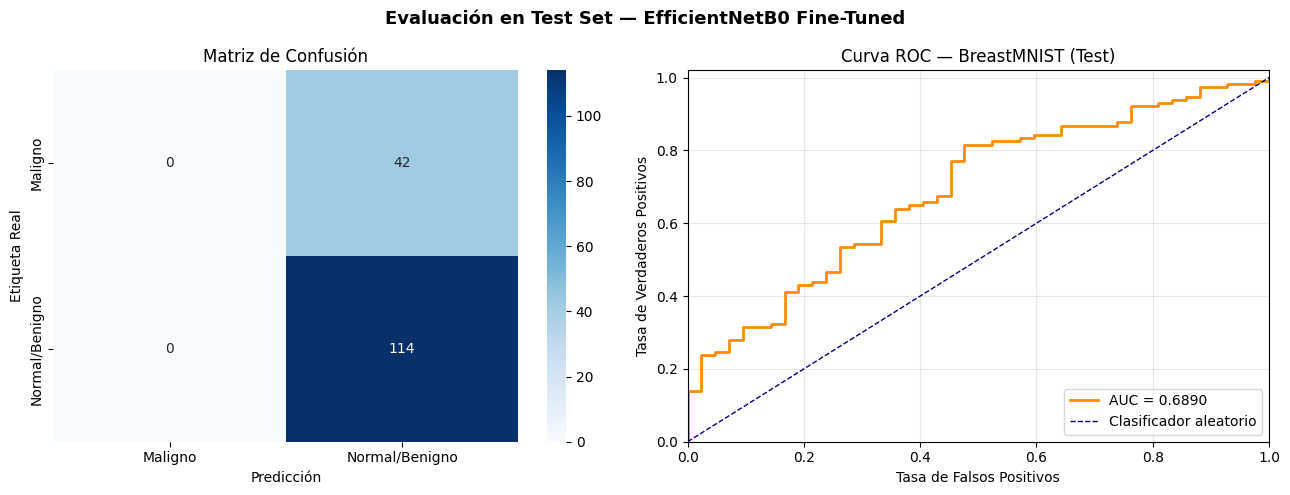

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Matriz de confusión ---
cm = confusion_matrix(y_test_p, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Maligno', 'Normal/Benigno'],
            yticklabels=['Maligno', 'Normal/Benigno'])
axes[0].set_title('Matriz de Confusión')
axes[0].set_ylabel('Etiqueta Real')
axes[0].set_xlabel('Predicción')

# --- Curva ROC ---
fpr, tpr, _ = roc_curve(y_test_p, y_pred_proba)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {auc:.4f}')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Clasificador aleatorio')
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0, 1.02])
axes[1].set_xlabel('Tasa de Falsos Positivos')
axes[1].set_ylabel('Tasa de Verdaderos Positivos')
axes[1].set_title('Curva ROC — BreastMNIST (Test)')
axes[1].legend(loc='lower right'); axes[1].grid(alpha=0.3)

plt.suptitle('Evaluación en Test Set — EfficientNetB0 Fine-Tuned', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 8. Visualización de predicciones individuales

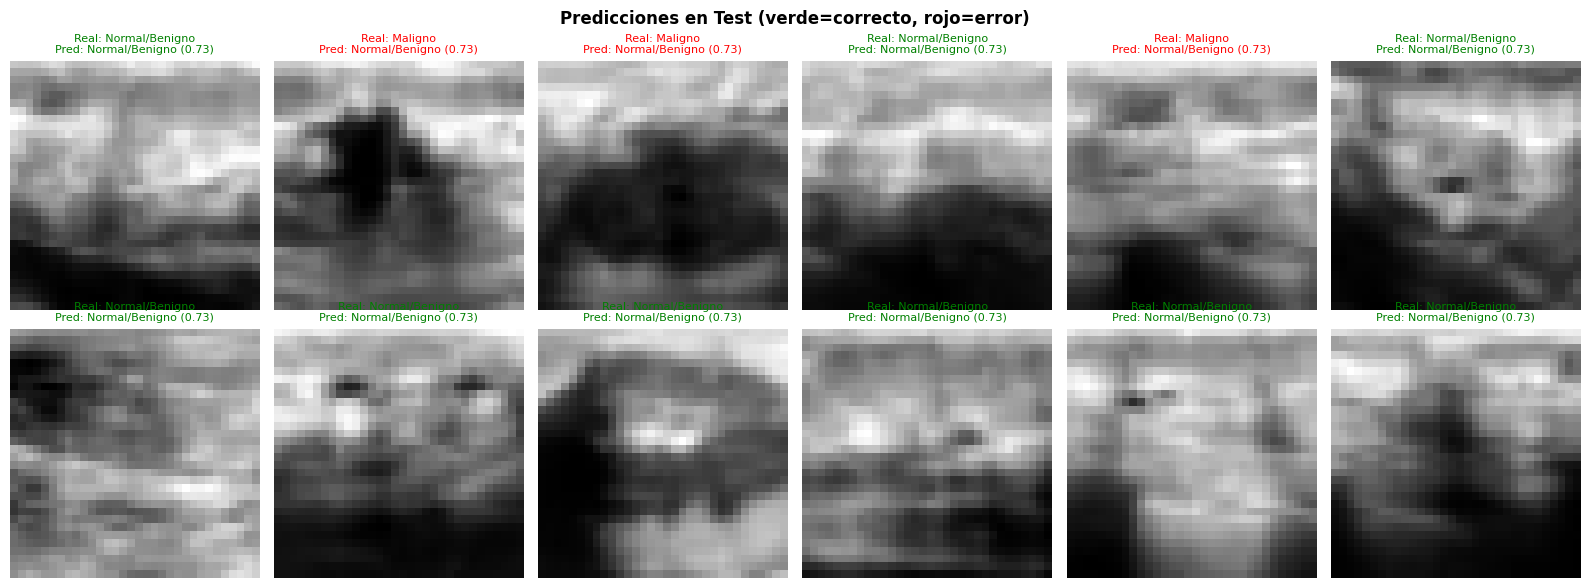

In [ ]:
# Mostrar 12 imágenes del test con su predicción y etiqueta real
n_show = 12
idxs = np.random.choice(len(X_test_p), n_show, replace=False)

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, idx in zip(axes.flatten(), idxs):
    img = X_test_p[idx, :, :, 0]  # canal 0 (son iguales los 3)
    pred  = y_pred[idx]
    real  = y_test_p[idx]
    prob  = y_pred_proba[idx]
    color = 'green' if pred == real else 'red'
    ax.imshow(img, cmap='gray')
    ax.set_title(
        f"Real: {class_names[real]}\nPred: {class_names[pred]} ({prob:.2f})",
        color=color, fontsize=8
    )
    ax.axis('off')

plt.suptitle('Predicciones en Test (verde=correcto, rojo=error)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 9. Resumen y conclusiones de la Entrega 1

### Configuración experimental
| Parámetro | Valor |
|---|---|
| Modelo base | EfficientNetB0 (ImageNet) |
| Resolución | 28×28 píxeles |
| Canales entrada | 1 (grayscale → replicado a 3) |
| Batch size | 32 |
| Fases de entrenamiento | 2 (Feature Extraction + Fine-Tuning) |
| LR Fase 1 | 1e-3 |
| LR Fase 2 | 1e-5 |
| Data augmentation | Flip, Rotation, Zoom |

### Métricas definidas (al menos 2 requeridas)
1. **AUC-ROC**: Principal métrica en clasificación médica por su robustez ante desbalance.
2. **F1-Score (macro)**: Considera tanto precisión como recall para ambas clases.
3. **Accuracy**: Métrica complementaria de referencia general.

### División hold-out
La división train/val/test es la **oficial de MedMNIST**, garantizando reproducibilidad y comparabilidad con la literatura.

### Observaciones sobre fine-tuning en resolución 28×28
EfficientNetB0 fue diseñado originalmente para imágenes de 224×224. Al usar 28×28, el modelo pierde capacidad de extracción de características espaciales en capas profundas. Sin embargo, el fine-tuning permite adaptar las representaciones al dominio médico de baja resolución.

In [ ]:
# Guardar el modelo entrenado (opcional, para entrega 2)
model.save('efficientnetb0_breastmnist_28px.h5')
print('Modelo guardado como efficientnetb0_breastmnist_28px.h5')

Modelo guardado como efficientnetb0_breastmnist_28px.h5
